In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("stores_sales_forecasting.csv", encoding="latin1")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 2121
Number of Columns: 21


In [7]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         2121 non-null   int64  
 1   Order ID       2121 non-null   object 
 2   Order Date     2121 non-null   object 
 3   Ship Date      2121 non-null   object 
 4   Ship Mode      2121 non-null   object 
 5   Customer ID    2121 non-null   object 
 6   Customer Name  2121 non-null   object 
 7   Segment        2121 non-null   object 
 8   Country        2121 non-null   object 
 9   City           2121 non-null   object 
 10  State          2121 non-null   object 
 11  Postal Code    2121 non-null   int64  
 12  Region         2121 non-null   object 
 13  Product ID     2121 non-null   object 
 14  Category       2121 non-null   object 
 15  Sub-Category   2121 non-null   object 
 16  Product Name   2121 non-null   object 
 17  Sales          2121 non-null   float64
 18  Quantity

In [9]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [10]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [11]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

print(df["Order Date"].dtype)

datetime64[ns]


In [12]:
df.describe()

,Row ID,Order Date,Postal Code,Sales,Quantity,Discount,Profit
count,2121.000000,2121,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000
mean,5041.643564,2016-04-30 03:54:13.748231680,55726.556341,349.834887,3.785007,0.173923,8.699327
min,1.000000,2014-01-06 00:00:00,1040.000000,1.892000,1.000000,0.000000,-1862.312400
25%,2568.000000,2015-05-26 00:00:00,22801.000000,47.040000,2.000000,0.000000,-12.849000
50%,5145.000000,2016-06-20 00:00:00,60505.000000,182.220000,3.000000,0.200000,7.774800
75%,7534.000000,2017-05-14 00:00:00,90032.000000,435.168000,5.000000,0.300000,33.726600
max,9991.000000,2017-12-30 00:00:00,99301.000000,4416.174000,14.000000,0.700000,1013.127000
std,2885.740258,NaN,32261.888225,503.179145,2.251620,0.181547,136.049246


In [13]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_quantity = df["Quantity"].sum()
average_sales = df["Sales"].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Sales per Record:", round(average_sales, 2))

Total Sales: 741999.8
Total Profit: 18451.27
Total Orders: 1764
Total Quantity Sold: 8028
Average Sales per Record: 349.83


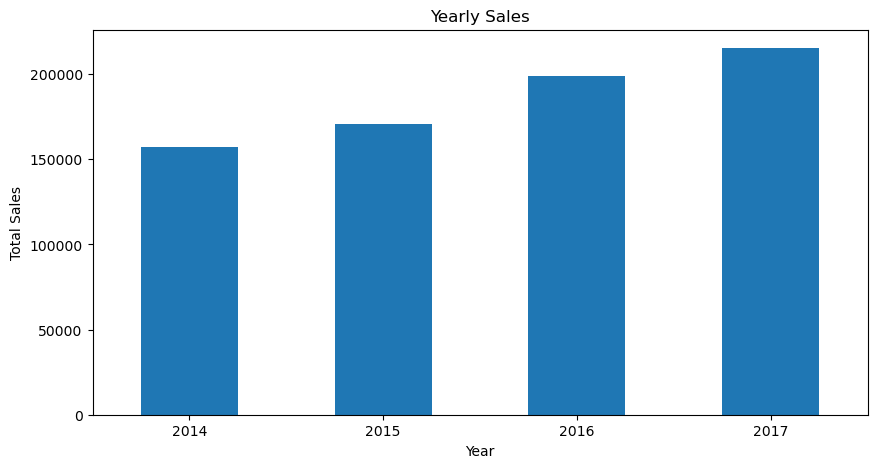

In [14]:
df["Year"] = df["Order Date"].dt.year

yearly_sales = df.groupby("Year")["Sales"].sum()

plt.figure(figsize=(10, 5))

yearly_sales.plot(kind="bar")

plt.title("Yearly Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()

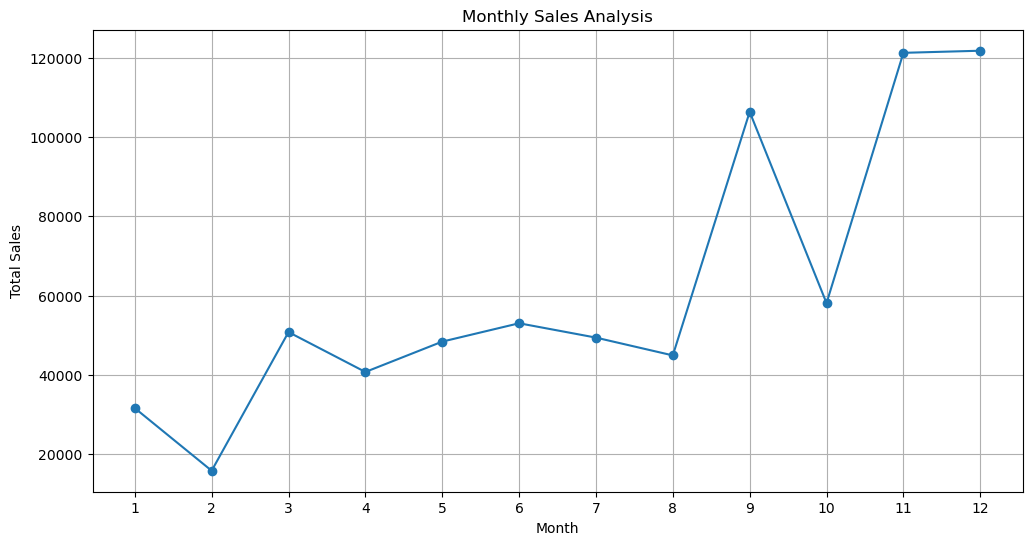

In [15]:
df["Month"] = df["Order Date"].dt.month

monthly_sales = df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(12, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

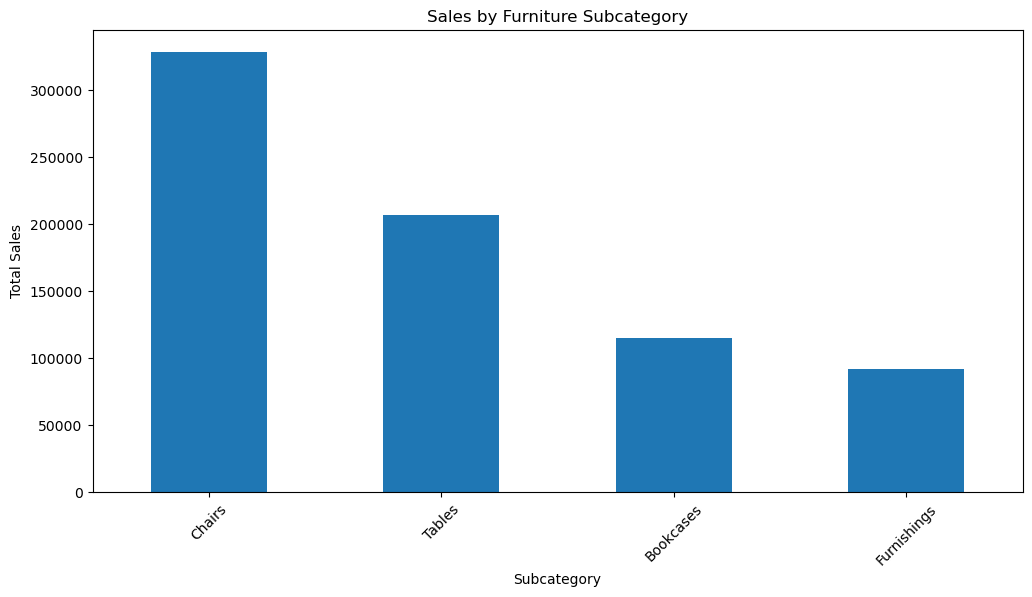

In [16]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

subcategory_sales.plot(kind="bar")

plt.title("Sales by Furniture Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

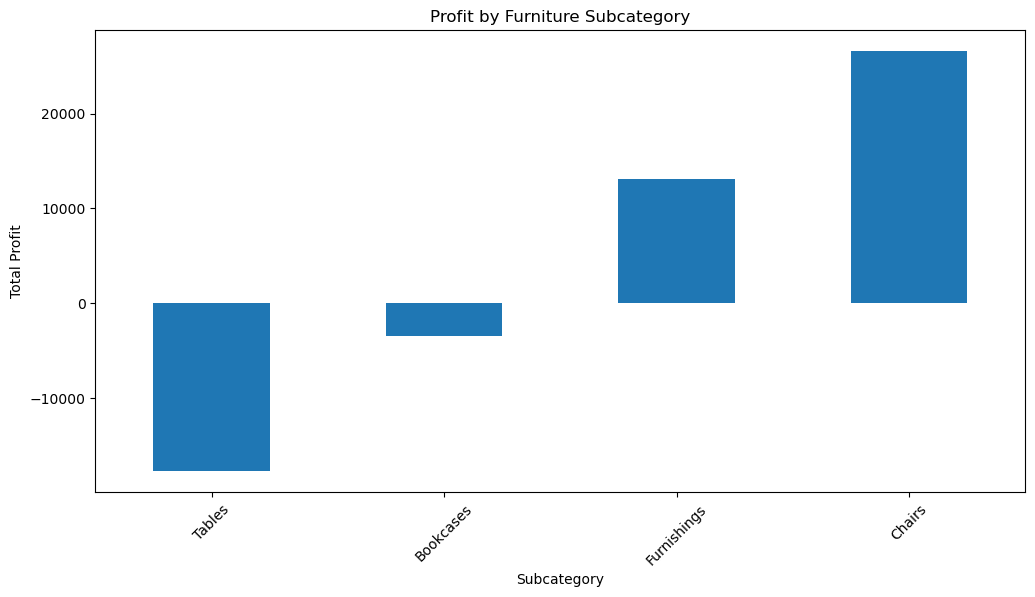

In [17]:
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()

plt.figure(figsize=(12, 6))

subcategory_profit.plot(kind="bar")

plt.title("Profit by Furniture Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)

plt.show()

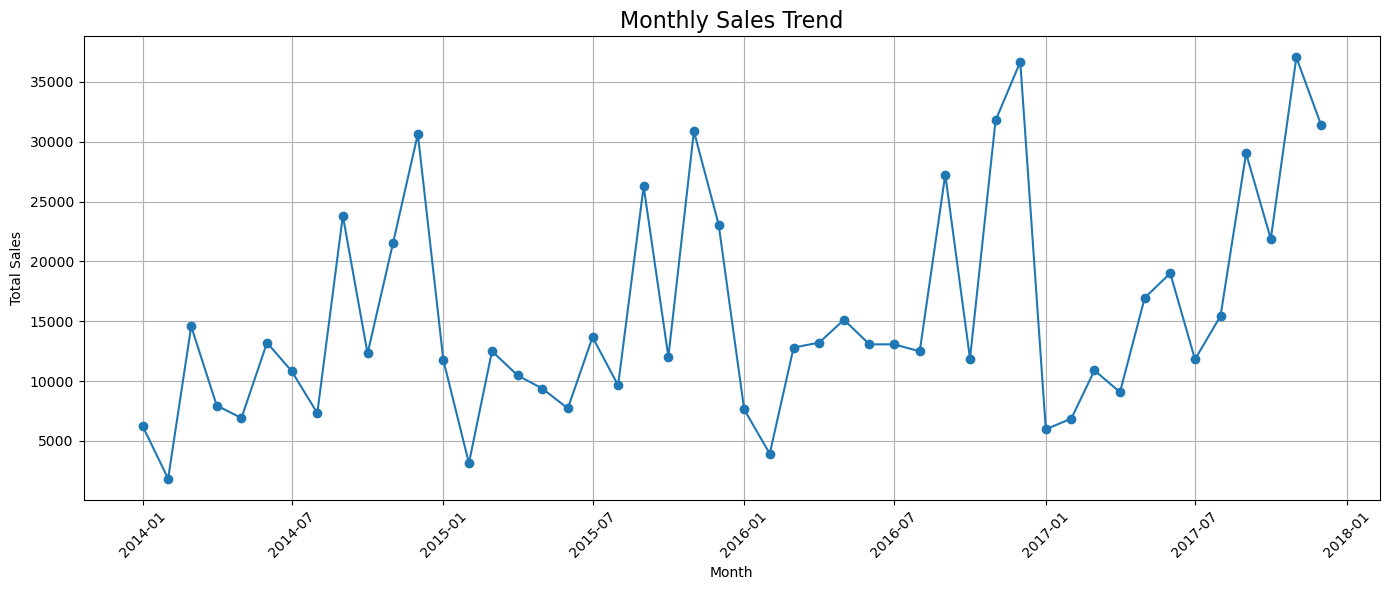

In [18]:
# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Create monthly sales data
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()

# Convert month periods into timestamps
monthly_sales.index = monthly_sales.index.to_timestamp()

# Plot monthly sales
plt.figure(figsize=(14, 6))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

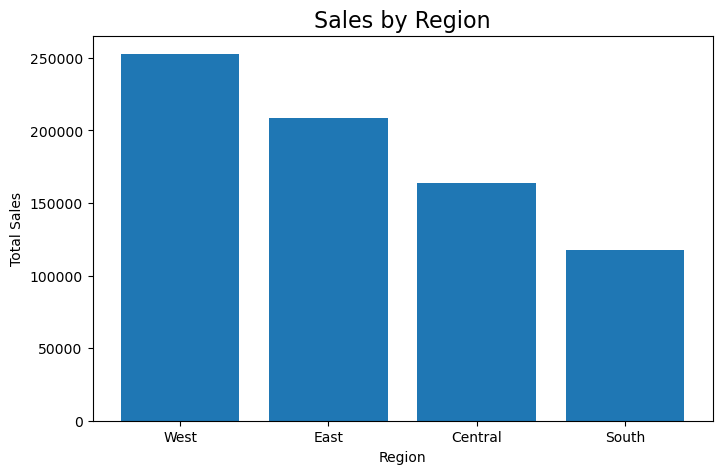

In [21]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

plt.bar(region_sales.index, region_sales.values)

plt.title("Sales by Region", fontsize=16)
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

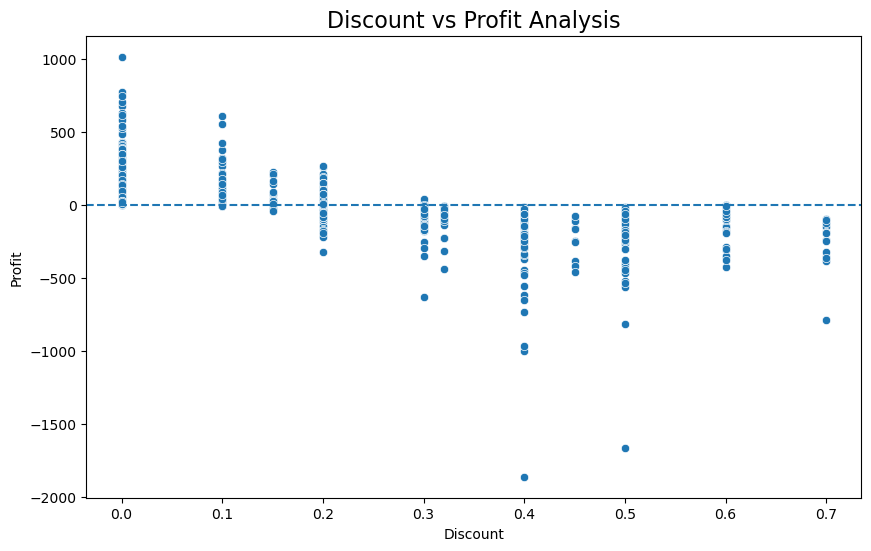

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="Discount", y="Profit")

plt.title("Discount vs Profit Analysis", fontsize=16)
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.axhline(y=0, linestyle="--")

plt.show()

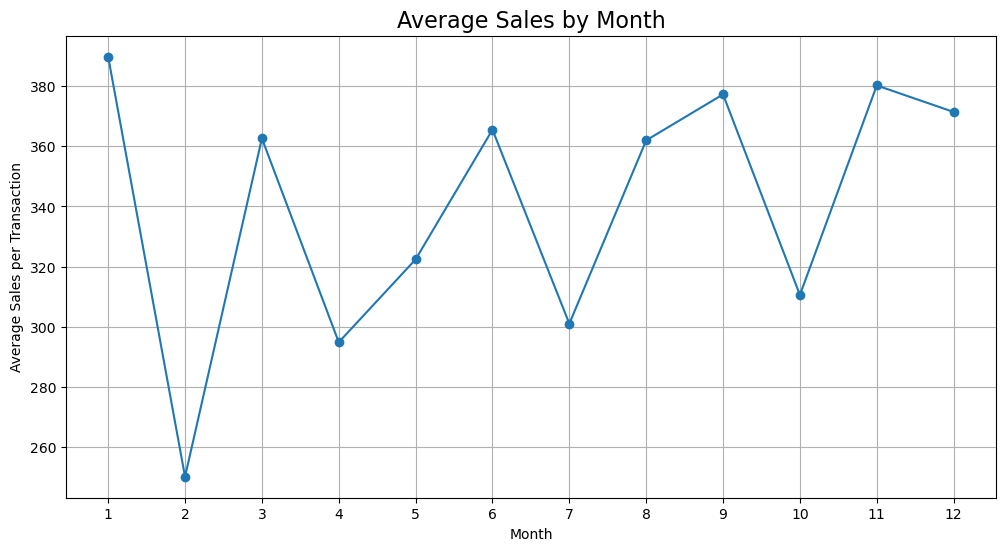

In [23]:
# Extract month number
df["Month_Number"] = df["Order Date"].dt.month

# Calculate average sales by month across all years
seasonal_sales = df.groupby("Month_Number")["Sales"].mean()

plt.figure(figsize=(12, 6))

plt.plot(seasonal_sales.index, seasonal_sales.values, marker="o")

plt.title("Average Sales by Month", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Sales per Transaction")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [24]:
# Create monthly total sales

monthly_data = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

monthly_data = monthly_data.to_frame()

monthly_data.index = monthly_data.index.to_timestamp()

monthly_data.head(10)

,Sales
Order Date,
2014-01-01,6242.5250
2014-02-01,1839.6580
2014-03-01,14573.9560
2014-04-01,7944.8370
2014-05-01,6912.7870
2014-06-01,13206.1256
2014-07-01,10821.0510
2014-08-01,7320.3465
2014-09-01,23816.4808


In [25]:
monthly_data.columns = ["Monthly_Sales"]

monthly_data.head(10)

,Monthly_Sales
Order Date,
2014-01-01,6242.5250
2014-02-01,1839.6580
2014-03-01,14573.9560
2014-04-01,7944.8370
2014-05-01,6912.7870
2014-06-01,13206.1256
2014-07-01,10821.0510
2014-08-01,7320.3465
2014-09-01,23816.4808


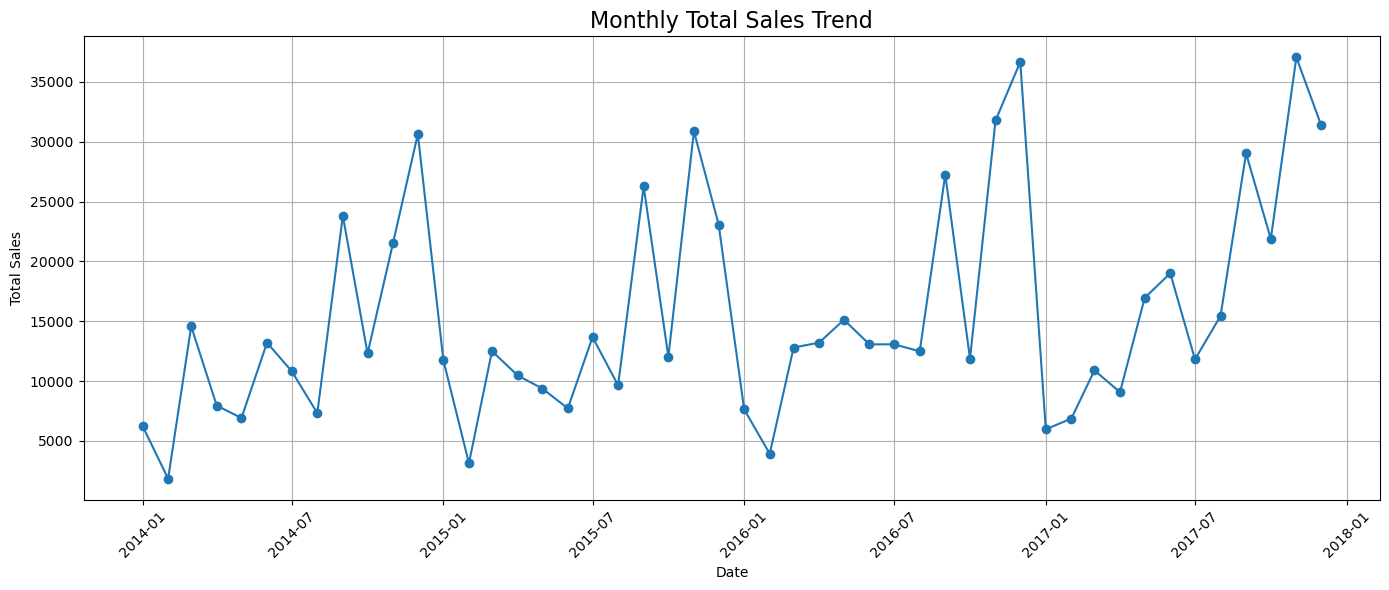

In [26]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_data.index,
    monthly_data["Monthly_Sales"],
    marker="o"
)

plt.title("Monthly Total Sales Trend", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
# Calculate monthly sales growth

monthly_data["Sales_Growth"] = monthly_data["Monthly_Sales"].pct_change() * 100

monthly_data.head(10)

,Monthly_Sales,Sales_Growth
Order Date,,
2014-01-01,6242.5250,NaN
2014-02-01,1839.6580,-70.530226
2014-03-01,14573.9560,692.210074
2014-04-01,7944.8370,-45.486064
2014-05-01,6912.7870,-12.990197
2014-06-01,13206.1256,91.039093
2014-07-01,10821.0510,-18.060366
2014-08-01,7320.3465,-32.350873
2014-09-01,23816.4808,225.346359


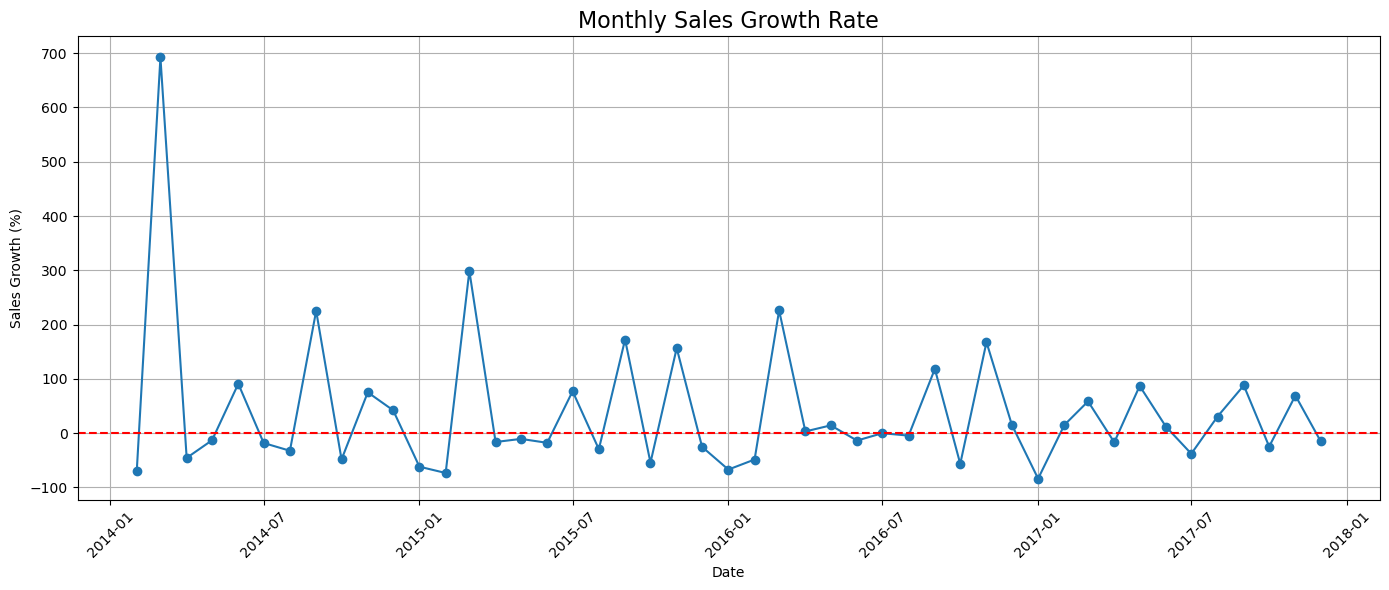

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_data.index,
    monthly_data["Sales_Growth"],
    marker="o"
)

plt.axhline(y=0, linestyle="--", color="red")

plt.title("Monthly Sales Growth Rate", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Sales Growth (%)")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
# Create a copy of our monthly sales dataset
ml_data = monthly_data.copy()

# Create time-based features
ml_data["Year"] = ml_data.index.year
ml_data["Month"] = ml_data.index.month

# Create a sequential time index
ml_data["Time_Index"] = range(len(ml_data))

# Display the dataset
ml_data.head()

,Monthly_Sales,Sales_Growth,Year,Month,Time_Index
Order Date,,,,,
2014-01-01,6242.525,NaN,2014,1,0
2014-02-01,1839.658,-70.530226,2014,2,1
2014-03-01,14573.956,692.210074,2014,3,2
2014-04-01,7944.837,-45.486064,2014,4,3
2014-05-01,6912.787,-12.990197,2014,5,4


In [31]:
# Define input features
X = ml_data[["Year", "Month", "Time_Index"]]

# Define target variable
y = ml_data["Monthly_Sales"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
            Year  Month  Time_Index
Order Date                         
2014-01-01  2014      1           0
2014-02-01  2014      2           1
2014-03-01  2014      3           2
2014-04-01  2014      4           3
2014-05-01  2014      5           4

Target variable:
Order Date
2014-01-01     6242.525
2014-02-01     1839.658
2014-03-01    14573.956
2014-04-01     7944.837
2014-05-01     6912.787
Freq: MS, Name: Monthly_Sales, dtype: float64


In [32]:
# Split the data chronologically

split_index = int(len(ml_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 38
Testing data: 10


In [33]:
from sklearn.linear_model import LinearRegression

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [34]:
# Predict sales for testing data

y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [35]:
# Create comparison table

comparison = pd.DataFrame({
    "Actual_Sales": y_test.values,
    "Predicted_Sales": y_pred
})

comparison.head(10)

,Actual_Sales,Predicted_Sales
0,10893.4448,10859.691790
1,9065.9581,12750.799134
2,16957.5582,14641.906478
3,19008.5867,16533.013821
4,11813.0220,18424.121165
5,15441.8740,20315.228509
6,29028.2060,22206.335853
7,21884.0682,24097.443197
8,37056.7150,25988.550541
9,31407.4668,27879.657885


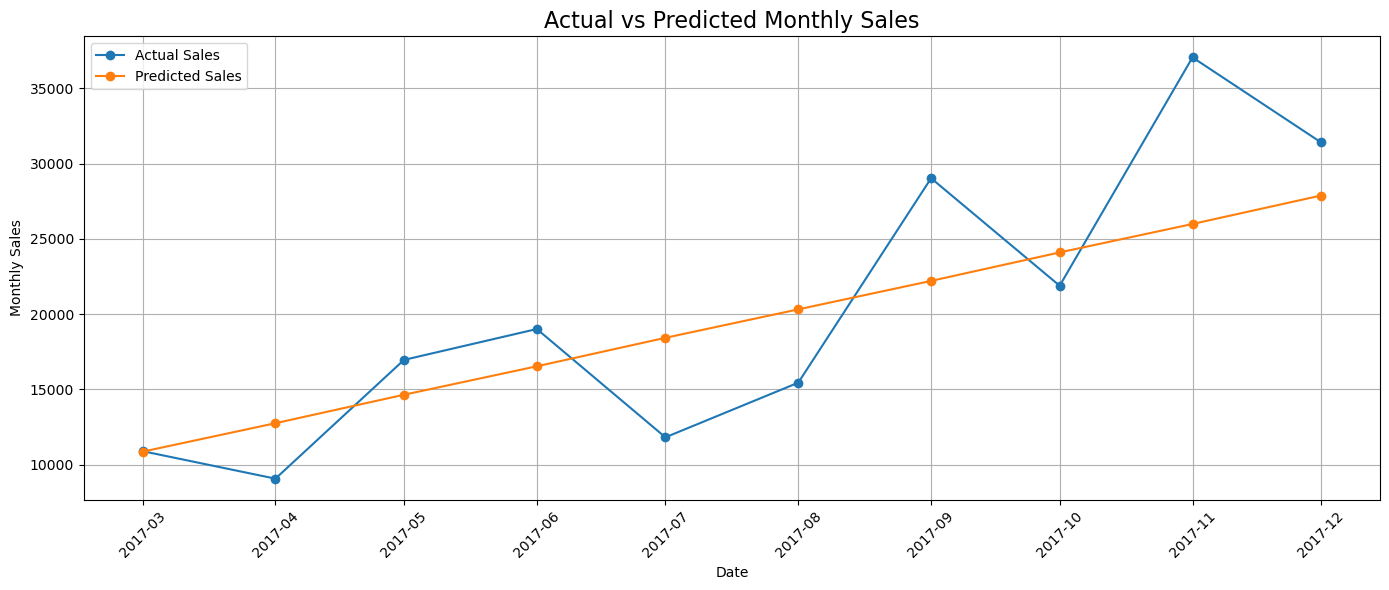

In [36]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test.values, marker="o", label="Actual Sales")
plt.plot(y_test.index, y_pred, marker="o", label="Predicted Sales")

plt.title("Actual vs Predicted Monthly Sales", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Monthly Sales")

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("Model Performance")
print("----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

Model Performance
----------------------
MAE: 4362.55
RMSE: 5281.22
MAPE: 22.99 %


In [41]:
# Create future time index
last_index = ml_data["Time_Index"].max()

future_index = np.arange(last_index + 1, last_index + 13)

# Create future dates
last_date = monthly_data.index.max()

future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=12,
    freq="MS"
)

# Create future features
future_features = pd.DataFrame({
    "Year": future_dates.year,
    "Month": future_dates.month,
    "Time_Index": future_index
})

# Predict future sales
future_predictions = model.predict(future_features)

# Create forecast dataframe
future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Sales": future_predictions
})

# Display forecast
future_forecast

,Date,Predicted_Sales
0,2018-01-01,8547.360377
1,2018-02-01,10438.467721
2,2018-03-01,12329.575065
3,2018-04-01,14220.682409
4,2018-05-01,16111.789753
5,2018-06-01,18002.897097
6,2018-07-01,19894.004441
7,2018-08-01,21785.111784
8,2018-09-01,23676.219128
9,2018-10-01,25567.326472


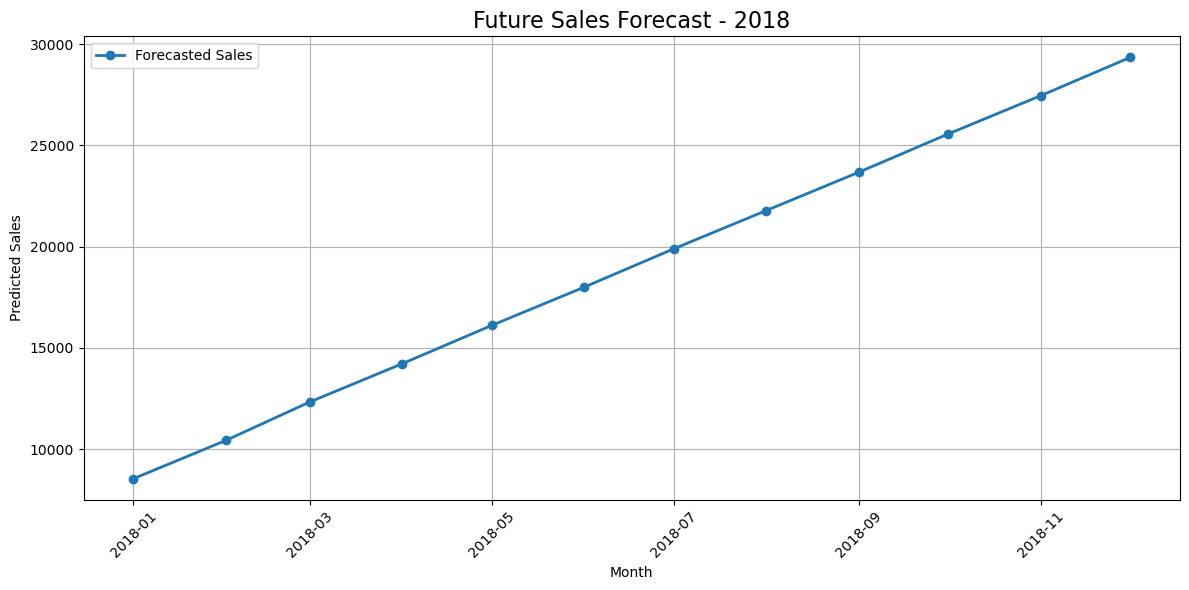

In [42]:
# Visualize future sales forecast

plt.figure(figsize=(12, 6))

plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted_Sales"],
    marker="o",
    linewidth=2,
    label="Forecasted Sales"
)

plt.title("Future Sales Forecast - 2018", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

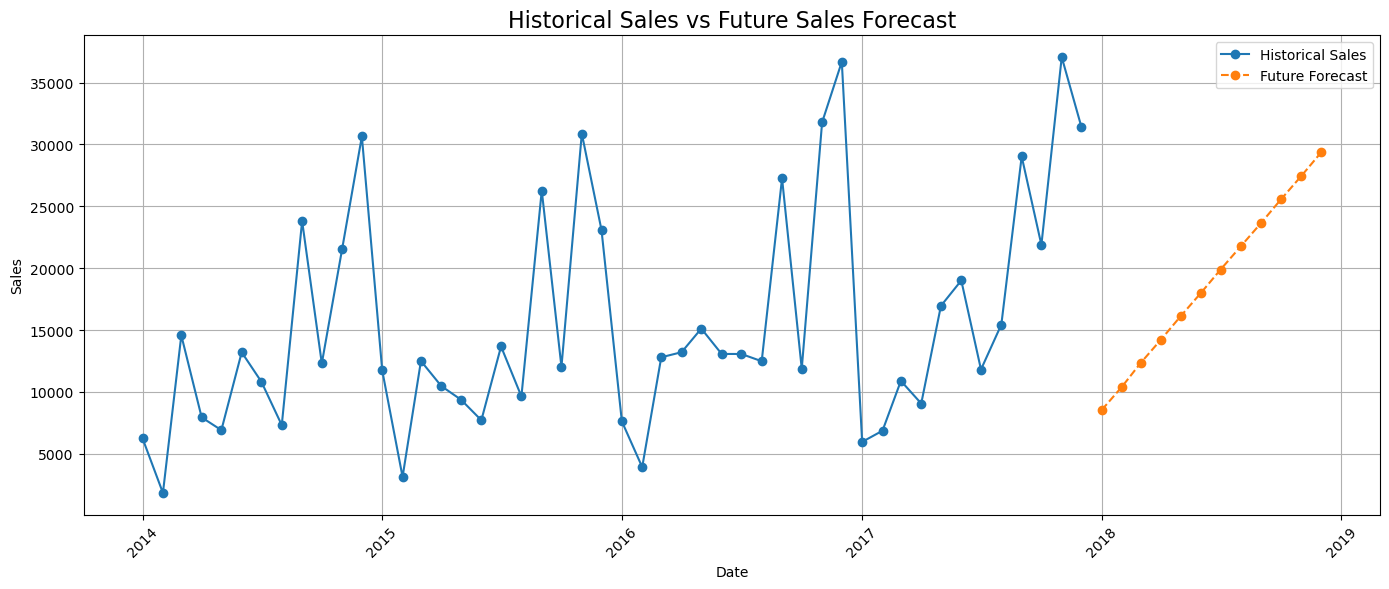

In [43]:
# Combine historical and future sales

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_data.index,
    monthly_data["Monthly_Sales"],
    label="Historical Sales",
    marker="o"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted_Sales"],
    label="Future Forecast",
    marker="o",
    linestyle="--"
)

plt.title("Historical Sales vs Future Sales Forecast", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()